# KNN y la nostalgia de la luz estelar
**Nadia Ramos González**

En esta parte de la exposición implementamos KNN desde cero para responder la pregunta de la historia: **¿qué es este destello?** Trabajamos con un conjunto de datos sintético de estrellas, galaxias y cuásares descritos por dos colores, para poder ver en un plano cómo decide el algoritmo.

## 0. Preparación del entorno

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier

plt.style.use('dark_background')
CLASES = ['Estrella', 'Galaxia', 'Cuásar']
COLORES = ['#FFD54F', '#BA68C8', '#4DD0E1']

## 1. Implementación de KNN

Retomamos la clase de nuestra práctica de KNN. El método `fit` sólo guarda los datos (KNN es *lazy*), `_distancias` calcula la distancia de Minkowski, `_k_vecinos` ordena y selecciona los $k$ más cercanos, y `_votar_predecir` aplica el voto mayoritario. Si hay empate, descartamos al vecino más lejano y volvemos a votar.

In [2]:
class KNNClassifier: 
    def __init__(self, n_neighbors=5, metric='euclidean', p=3):
        """
        Parámetros: 
        ----------
        n_neighbors: int, default=5
            Número de vecinos más cercanos a considerar (k). 
        metric: str, default='euclidean'
            Métrica de distancia: 'euclidean', 'manhattan' o 'minkowski'.
        p: int o float, default=3
            Exponente para la distancia de Minkowski. Solo se usa si metric='minkowski'.
        """
    
        #Verificamos que las distancias a utilizar sean válidas
        if metric not in ('euclidean', 'manhattan', 'minkowski'):
            raise ValueError("la distancia debe ser 'euclidean', 'manhattan' o 'minkowski'")
        #Recordemos que la distancia de Minkowski requiere que p sea mayor o igual a 1, donde esta métrica es una generalización de la distancia euclidiana y manhattan.
        if metric == 'minkowski' and p < 1:
            raise ValueError("Minkowski requiere p >= 1") 


        # Guardamos los hiperparámetros como atributos de la instancia
        self.n_neighbors = n_neighbors
        self.metric = metric
        self.p = p


    def fit(self, X, y):
        """  
        Almacena el conjunto de datos de entrenamiento (método no paramétrico).
        Parámetros:
        ----------
        X: np.ndarray de dimension (n_muestras, n_características)
        y: np.ndarray de dimension (n_muestras,)
        Donde nd array puede entonces tener múltiples dimensiones.
        """
        #Recordemos que self.X_train es un atributo de una clase que almacena los datos de entrenamiento de las características de un modelo
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)
        if self.n_neighbors > len(self.X_train):
            raise ValueError("n_neighbors no puede ser mayor que el número de muestras de entrenamiento")
        return self

    
    def _distancias(self, x):
        """
        Calcula la distancia elegida (euclidiana, manhattan o minkowski) de 
        una muestra x a todas las muestras de entrenamiento.

        Parámetros:
        ----------
        x: np.ndarray de dimensión (n_características,)

        Salida:
        np.ndarray de dimensión (n_muestras,) con las distancias calculadas.
        """
        #Diferencia absoluta entre cada muestra de entrenamiento y la muestra x
        diff = np.abs(self.X_train - x)
        #Distancia euclidiana 
        if self.metric == 'euclidean':
            distancias = np.sqrt(np.sum(diff ** 2, axis=1))
        #Distancia Manhattan
        elif self.metric == 'manhattan':
            distancias = np.sum(diff, axis=1)
        else:  # 'minkowski'
            distancias = np.sum(diff ** self.p, axis=1) ** (1 / self.p)
        return distancias


    
    def _k_vecinos(self, x):
        """
        Encuentra los índices de las k muestras de entrenamiento más cercanas a x,
        ordenados de la más cercana a la más lejana.

        Parámetros
        ----------
        x : np.ndarray de dimensión (n_características,)

        Salida
        ------
        np.ndarray de dimensión (n_neighbors,)
            Índices de los vecinos en X_train, ordenados por distancia.
        """
        distancias = self._distancias(x)
        k = self.n_neighbors
        idx = np.argpartition(distancias, k - 1)[:k]
        return idx[np.argsort(distancias[idx])]
    
    
    def _votar_predecir(self, x):
        """
        Predice la etiqueta de una  muestra x por voto mayoritario de sus
        k vecinos más cercanos. Si hay empate, reduce k en 1 hasta que haya una etiqueta ganadora.

        Parámetros
        ----------
        x : np.ndarray de dimensión (n_características,)

        Salida
        ------
        La etiqueta más frecuente entre los vecinos considerados.
        """
        idx = self._k_vecinos(x)              # ordenados de menor a mayor distancia
        etiquetas = self.y_train[idx]

        for k in range(len(etiquetas), 0, -1):
            valores, cuentas = np.unique(etiquetas[:k], return_counts=True)
            maximo = cuentas.max()
            if np.sum(cuentas == maximo) == 1:     # no hay empate
                return valores[np.argmax(cuentas)]


    def predict(self, X):
        """
        Retorna las etiquetas de clase predichas para cada muestra de entrada.

        X : np.ndarray de dimensión (m_muestras, n_características)
        Retorna : np.ndarray de dimensión (m_muestras,)
        """
        X = np.asarray(X, dtype=float)
        return np.array([self._votar_predecir(x) for x in X])
    
    def score(self, X, y):
        """Calcula y retorna la exactitud (accuracy) sobre el conjunto dado."""
        return np.mean(self.predict(X) == np.asarray(y))

## 2. El ejemplo a mano

Antes de pasar a muchos datos, comprobamos con la clase el ejemplo que resolvimos en el pizarrón: seis destellos y un destello nuevo $\mathbf{x}_q = (3, 4)$.

In [3]:
X_mano = np.array([[1, 2], [2, 1], [4, 6], [5, 4], [8, 8], [7, 9]])
y_mano = np.array(['Cuásar', 'Cuásar', 'Estrella', 'Estrella', 'Galaxia', 'Galaxia'])
x_q = np.array([3, 4])

knn_mano = KNNClassifier(n_neighbors=3).fit(X_mano, y_mano)
tabla = pd.DataFrame({'destello': list('ABCDEF'),
                      'distancia': knn_mano._distancias(x_q).round(2),
                      'clase': y_mano}).sort_values('distancia')
print(tabla.to_string(index=False))

for k in [3, 4]:
    pred = KNNClassifier(n_neighbors=k).fit(X_mano, y_mano).predict([x_q])[0]
    print(f"k = {k}: el destello es {pred}")

destello  distancia    clase
       D       2.00 Estrella
       C       2.24 Estrella
       A       2.83   Cuásar
       B       3.16   Cuásar
       E       6.40  Galaxia
       F       6.40  Galaxia
k = 3: el destello es Estrella
k = 4: el destello es Estrella


Obtenemos las mismas distancias que a mano. Con $k = 4$ hay empate (2 estrellas y 2 cuásares); nuestra regla descarta al vecino más lejano y vuelve a votar con $k = 3$, así que el resultado sigue siendo **Estrella**.

## 3. Un cielo sintético

Generamos 450 destellos (150 por clase) con dos colores: $u-g$ (ultravioleta menos verde) y $g-r$ (verde menos rojo). Los valores son sintéticos, aunque inspirados en el comportamiento típico de estos objetos: los cuásares tienen exceso de luz ultravioleta ($u-g$ pequeño), las galaxias tienden a ser más rojas y las estrellas forman una franja intermedia que se traslapa con las galaxias.

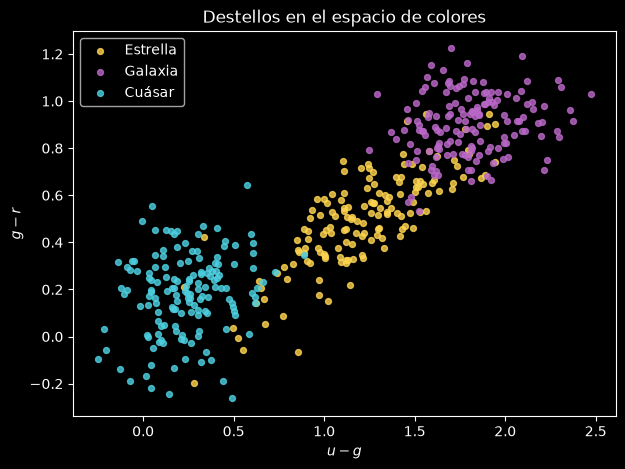

In [4]:
rng = np.random.default_rng(42)
parametros = {
    'Estrella': ([1.20, 0.50], [[0.12, 0.06], [0.06, 0.05]]),
    'Galaxia':  ([1.80, 0.90], [[0.05, 0.01], [0.01, 0.02]]),
    'Cuásar':   ([0.25, 0.20], [[0.04, 0.00], [0.00, 0.03]]),
}
X = np.vstack([rng.multivariate_normal(m, c, 150) for m, c in parametros.values()])
y = np.repeat(CLASES, 150)

fig, ax = plt.subplots(figsize=(7, 5))
for clase, color in zip(CLASES, COLORES):
    ax.scatter(*X[y == clase].T, s=18, c=color, label=clase, alpha=0.8)
ax.set_xlabel('$u - g$')
ax.set_ylabel('$g - r$')
ax.set_title('Destellos en el espacio de colores')
ax.legend()
plt.show()

## 4. ¿Qué es este destello?

Separamos 80 % de los datos como memoria del algoritmo (entrenamiento) y 20 % como prueba. Después tomamos un destello nuevo y seguimos los cuatro pasos: calcular distancias, ordenar, elegir a los $k = 5$ vecinos más cercanos y votar.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y)

knn = KNNClassifier(n_neighbors=5).fit(X_train, y_train)
destello = np.array([1.5, 0.72])

# Pasos 1 y 2: distancias y vecinos más cercanos
idx = knn._k_vecinos(destello)
vecinos = pd.DataFrame({'u-g': X_train[idx, 0].round(2), 'g-r': X_train[idx, 1].round(2),
                        'distancia': knn._distancias(destello)[idx].round(3),
                        'clase': y_train[idx]})
print(vecinos.to_string(index=False))

# Pasos 3 y 4: votación y clasificación
print('\nVotos:', {c: int(n) for c, n in pd.Series(y_train[idx]).value_counts().items()})
print('El destello es:', knn.predict([destello])[0])

 u-g  g-r  distancia    clase
1.48 0.73      0.022 Estrella
1.51 0.75      0.032  Galaxia
1.54 0.72      0.038 Estrella
1.46 0.74      0.040  Galaxia
1.50 0.66      0.059 Estrella

Votos: {'Estrella': 3, 'Galaxia': 2}
El destello es: Estrella


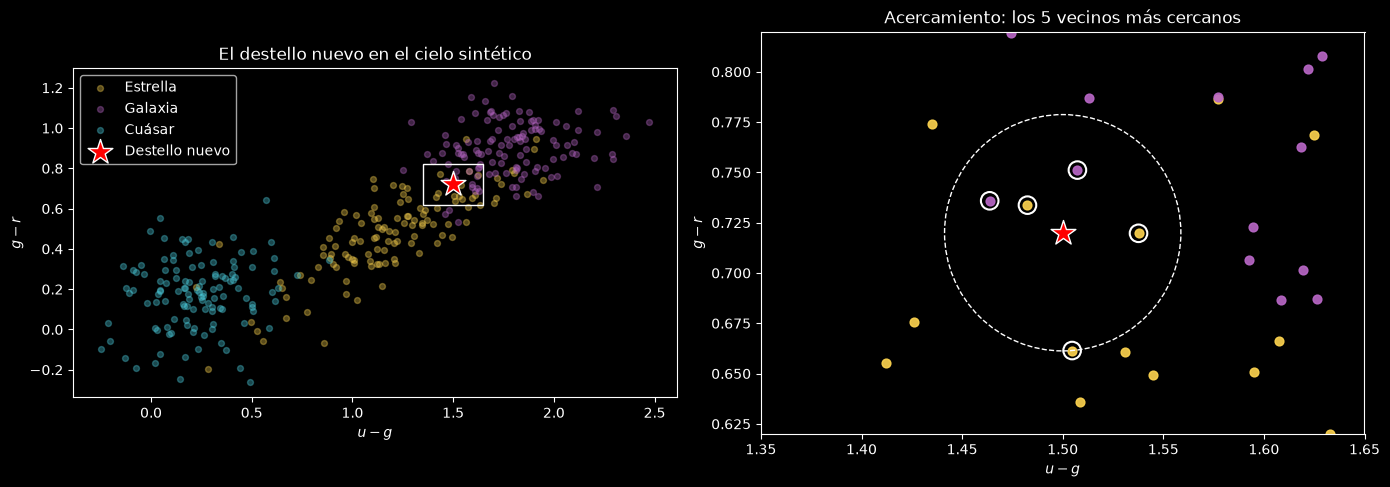

In [6]:
radio = knn._distancias(destello)[idx].max()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, zoom in zip(axes, [False, True]):
    for clase, color in zip(CLASES, COLORES):
        ax.scatter(*X_train[y_train == clase].T, s=40 if zoom else 18, c=color, label=clase,
                   alpha=0.9 if zoom else 0.35)
    ax.scatter(*destello, marker='*', s=350, c='red', edgecolors='white', label='Destello nuevo')
    ax.set_xlabel('$u - g$')
    ax.set_ylabel('$g - r$')
    ax.set_aspect('equal')
    if zoom:
        ax.scatter(*X_train[idx].T, s=160, facecolors='none', edgecolors='white', linewidths=1.5)
        ax.add_patch(plt.Circle(destello, radio, fill=False, ls='--', color='white'))
        ax.set_xlim(destello[0] - 0.15, destello[0] + 0.15)
        ax.set_ylim(destello[1] - 0.1, destello[1] + 0.1)
        ax.set_title('Acercamiento: los 5 vecinos más cercanos')
    else:
        ax.add_patch(plt.Rectangle(destello - [0.15, 0.1], 0.3, 0.2, fill=False, color='white'))
        ax.set_title('El destello nuevo en el cielo sintético')
        ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

## 5. Cómo cambia la decisión con $k$

Clasificamos cada punto del plano para dibujar la frontera de decisión. Con $k = 1$ la frontera sigue cada punto de entrenamiento, incluido el ruido (alta varianza); con $k$ grande se suaviza demasiado (alto sesgo).

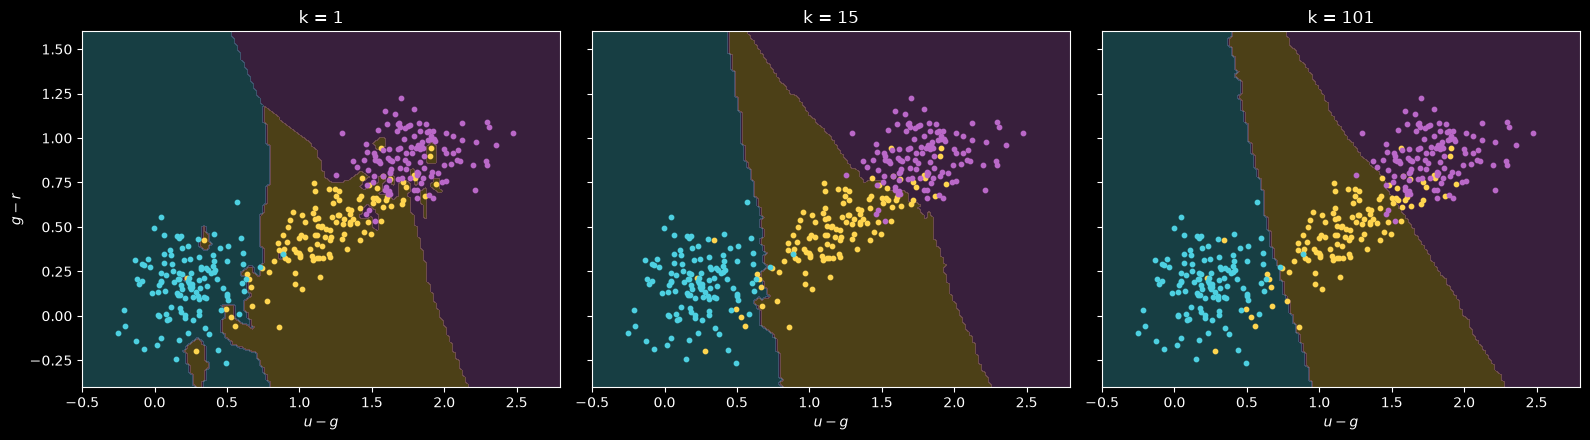

In [7]:
xx, yy = np.meshgrid(np.linspace(-0.5, 2.8, 150), np.linspace(-0.4, 1.6, 150))
malla = np.c_[xx.ravel(), yy.ravel()]
a_num = {c: i for i, c in enumerate(CLASES)}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, k in zip(axes, [1, 15, 101]):
    Z = KNNClassifier(n_neighbors=k).fit(X_train, y_train).predict(malla)
    Z = np.vectorize(a_num.get)(Z).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5, 2.5], cmap=ListedColormap(COLORES), alpha=0.3)
    for clase, color in zip(CLASES, COLORES):
        ax.scatter(*X_train[y_train == clase].T, s=10, c=color)
    ax.set_title(f'k = {k}')
    ax.set_xlabel('$u - g$')
axes[0].set_ylabel('$g - r$')
plt.tight_layout()
plt.show()

## 6. Elección de $k$

Para no elegir $k$ con los mismos datos con los que reportamos el resultado, separamos una parte del entrenamiento como validación. Probamos valores impares de $k$ y nos quedamos con el de mayor exactitud en validación.

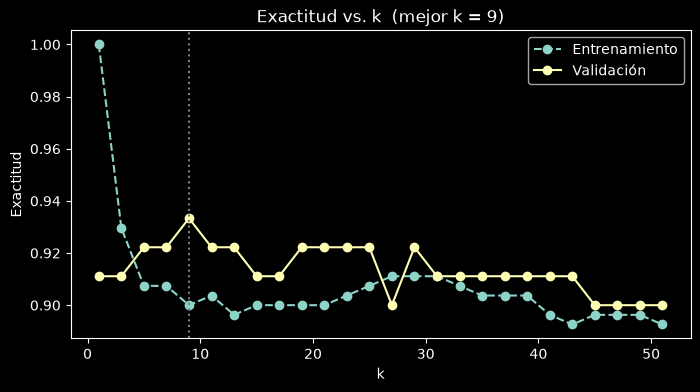

In [8]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=0, stratify=y_train)

ks = np.arange(1, 52, 2)
acc_tr = [KNNClassifier(n_neighbors=k).fit(X_tr, y_tr).score(X_tr, y_tr) for k in ks]
acc_val = [KNNClassifier(n_neighbors=k).fit(X_tr, y_tr).score(X_val, y_val) for k in ks]
k_opt = int(ks[np.argmax(acc_val)])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ks, acc_tr, 'o--', label='Entrenamiento')
ax.plot(ks, acc_val, 'o-', label='Validación')
ax.axvline(k_opt, color='gray', ls=':')
ax.set_xlabel('k')
ax.set_ylabel('Exactitud')
ax.set_title(f'Exactitud vs. k  (mejor k = {k_opt})')
ax.legend()
plt.show()

## 7. Evaluación final

k = 9, exactitud en prueba: 0.944
Coincidencia con scikit-learn: 1.000


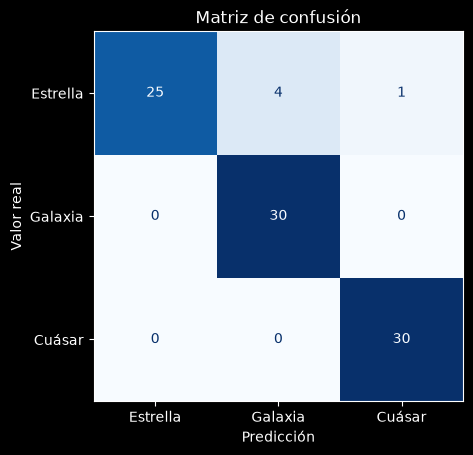

In [9]:
modelo = KNNClassifier(n_neighbors=k_opt).fit(X_train, y_train)
y_pred = modelo.predict(X_test)
print(f'k = {k_opt}, exactitud en prueba: {np.mean(y_pred == y_test):.3f}')

# Comparación con scikit-learn
sk = KNeighborsClassifier(n_neighbors=k_opt).fit(X_train, y_train)
print(f'Coincidencia con scikit-learn: {np.mean(sk.predict(X_test) == y_pred):.3f}')

cm = confusion_matrix(y_test, y_pred, labels=CLASES)
disp = ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(cmap='Blues', colorbar=False)
disp.ax_.set(xlabel='Predicción', ylabel='Valor real', title='Matriz de confusión')
plt.show()

## 8. Importancia de la normalización

Agregamos una tercera variable, un flujo en unidades arbitrarias con valores de miles, que **no contiene información** sobre la clase. Como KNN depende de distancias, esta variable domina la suma y el algoritmo deja de ver los colores. Al estandarizar, cada variable vuelve a pesar lo mismo.

In [10]:
flujo = rng.normal(5000, 1500, size=(len(X), 1))
X3 = np.hstack([X, flujo])
X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y, test_size=0.2, random_state=0, stratify=y)

acc_crudo = KNNClassifier(n_neighbors=k_opt).fit(X3_train, y3_train).score(X3_test, y3_test)

scaler = StandardScaler().fit(X3_train)   # se ajusta sólo con entrenamiento
acc_esc = KNNClassifier(n_neighbors=k_opt).fit(scaler.transform(X3_train), y3_train) \
                                          .score(scaler.transform(X3_test), y3_test)

print(f'Sin escalar: {acc_crudo:.3f}')
print(f'Escalado:    {acc_esc:.3f}')

Sin escalar: 0.344
Escalado:    0.900




## 9. Conclusiones

Con $k = 9$, elegido en validación, nuestro KNN alcanzó una exactitud de **94.4 %** en prueba (85 de 90 destellos). Sus predicciones coinciden al 100 % con las de `KNeighborsClassifier` de scikit-learn, lo que confirma que la implementación es correcta.

**Errores.** Galaxias y cuásares se clasificaron sin error. Los 5 errores fueron estrellas: 4 confundidas con galaxias y 1 con un cuásar. Esto coincide con la geometría del cielo sintético: la franja de estrellas se traslapa con la nube de galaxias, y en esa zona los vecinos de un destello pueden ser de ambas clases. KNN no puede separar lo que los colores no separan; es un límite de la información disponible, no del algoritmo.

**Efecto de $k$.** Con $k = 1$ la frontera de decisión sigue cada punto de entrenamiento, incluso los atípicos (alta varianza). Con $k = 101$ se suaviza demasiado y empieza a invadir regiones de otras clases (alto sesgo). Un $k$ intermedio, como $k = 9$, promedia lo suficiente para ignorar el ruido sin perder la localidad.

**Normalización.** Al agregar una variable de flujo con valores de miles, la exactitud cayó a **34.4 %**, prácticamente lo mismo que adivinar entre tres clases ($1/3$). Esa variable dominó la distancia y el algoritmo dejó de ver los colores. Al estandarizar, la exactitud volvió a **90.0 %**. La diferencia con el 94.4 % original se debe a que el flujo, aun escalado, sigue siendo ruido que se suma a la distancia.

En resumen, KNN reconoce bien qué es cada destello a partir de sus colores, siempre que la memoria sea representativa, la distancia compare variables en la misma escala y $k$ equilibre la localidad con la estabilidad.